# Preprocessing

since clustering is unsupervised the main jobs here are to pick features that describe a booking at the moment it is made and remove any columns that might cause data leakage

| Part | Content |
|---|---|
| 1 | Seeing the data |
| 2 | Feature engineering |
| 3 | EDA: distributions |
| 4 | EDA: correlation between candidate features |
| 5 | EDA: leakage checks (outcome proxies) |
| 6 | Feature selection |
| 7 | Transformation and scaling |
| 8 | Checks on the final matrix |
| 9 | Save the dataset |

## 1 Seeing the data

In [461]:
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

darkjungle = "#1e201f"
mediumjungle = "#193a31"
deepgreen = "#1d6c61"
verdigris = "#3e89ab"
forestgreen = "#5aa371"
mist = "#e6eeeb"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": mist, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.edgecolor": mediumjungle,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": darkjungle, "axes.labelcolor": darkjungle, "axes.titlecolor": mediumjungle,
    "xtick.color": mediumjungle, "ytick.color": mediumjungle,
    "axes.prop_cycle": plt.cycler(color=[deepgreen, verdigris, forestgreen, mediumjungle]),
})
# cluster colours (team palette + a few distinct tones)
CLUSTER_COLORS = [deepgreen, verdigris, "#d08c3a", "#8a5aa3", forestgreen, "#c4515a",
                  "#5a6fa3", "#9aa83e", "#a37a5a", "#6b6b6b"]
div_cmap = LinearSegmentedColormap.from_list("div", [verdigris, "#ffffff", deepgreen])

IMG_DIR = "figs/preprocessing"
os.makedirs(IMG_DIR, exist_ok=True)

def save(name):
    plt.savefig(f"{IMG_DIR}/{name}", dpi=150)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [462]:
raw = pd.read_csv("../H2_cleaned.csv")
print("rows:", len(raw), " columns:", raw.shape[1], " missing values:", int(raw.isna().sum().sum()))
raw.head()

rows: 48991  columns: 31  missing values: 0


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Meal,Country,MarketSegment,DistributionChannel,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,ReservedRoomType,AssignedRoomType,BookingChanges,DepositType,Agent,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,HasCompany
0,1,88,2015,July,27,1,0,4,2,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,0,Transient,76.5,0,1,Canceled,2015-07-01,0
1,1,65,2015,July,27,1,0,4,1,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,0,Transient,68.0,0,1,Canceled,2015-04-30,0
2,1,92,2015,July,27,1,2,4,2,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,0,Transient,76.5,0,2,Canceled,2015-06-23,0
3,1,100,2015,July,27,2,0,2,2,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,0,Transient,76.5,0,1,Canceled,2015-04-02,0
4,1,79,2015,July,27,2,0,3,2,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,0,Transient,76.5,0,1,Canceled,2015-06-25,0


In [463]:
overview = pd.DataFrame({"dtype": raw.dtypes.astype(str), "unique values": raw.nunique()})
overview

,dtype,unique values
IsCanceled,int64,2
LeadTime,int64,275
ArrivalDateYear,int64,3
ArrivalDateMonth,str,12
ArrivalDateWeekNumber,int64,53
ArrivalDateDayOfMonth,int64,31
StaysInWeekendNights,int64,5
StaysInWeekNights,int64,7
Adults,int64,4
Children,int64,4


## 2 Feature engineering

### new cols
* **TotalNights** = weekend nights + week nights (total length of stay)
* **TotalGuests** = adults + children + babies (party size)
* **Segment**: MarketSegment with its rare values handled. dropping the singular Undefined row , and merging Aviation is merged into Corporate since its assumed that both will have business rates


In [464]:
print("MarketSegment before merging:")
print(raw["MarketSegment"].value_counts().to_string())

df = raw[raw["MarketSegment"] != "Undefined"].reset_index(drop=True)
df["TotalNights"] = df["StaysInWeekendNights"] + df["StaysInWeekNights"]
df["TotalGuests"] = df["Adults"] + df["Children"] + df["Babies"]
df["Segment"] = df["MarketSegment"].replace({"Aviation": "Corporate"})


print("\nSegment after merging:")
print(df["Segment"].value_counts().to_string())
print("\nrows:", len(df))

MarketSegment before merging:
MarketSegment
Online TA        32980
Offline TA/TO     6551
Direct            5071
Corporate         2170
Groups            1956
Aviation           201
Complementary       61
Undefined            1

Segment after merging:
Segment
Online TA        32980
Offline TA/TO     6551
Direct            5071
Corporate         2371
Groups            1956
Complementary       61

rows: 48990


## 3 EDA: distributions


Numerical columns

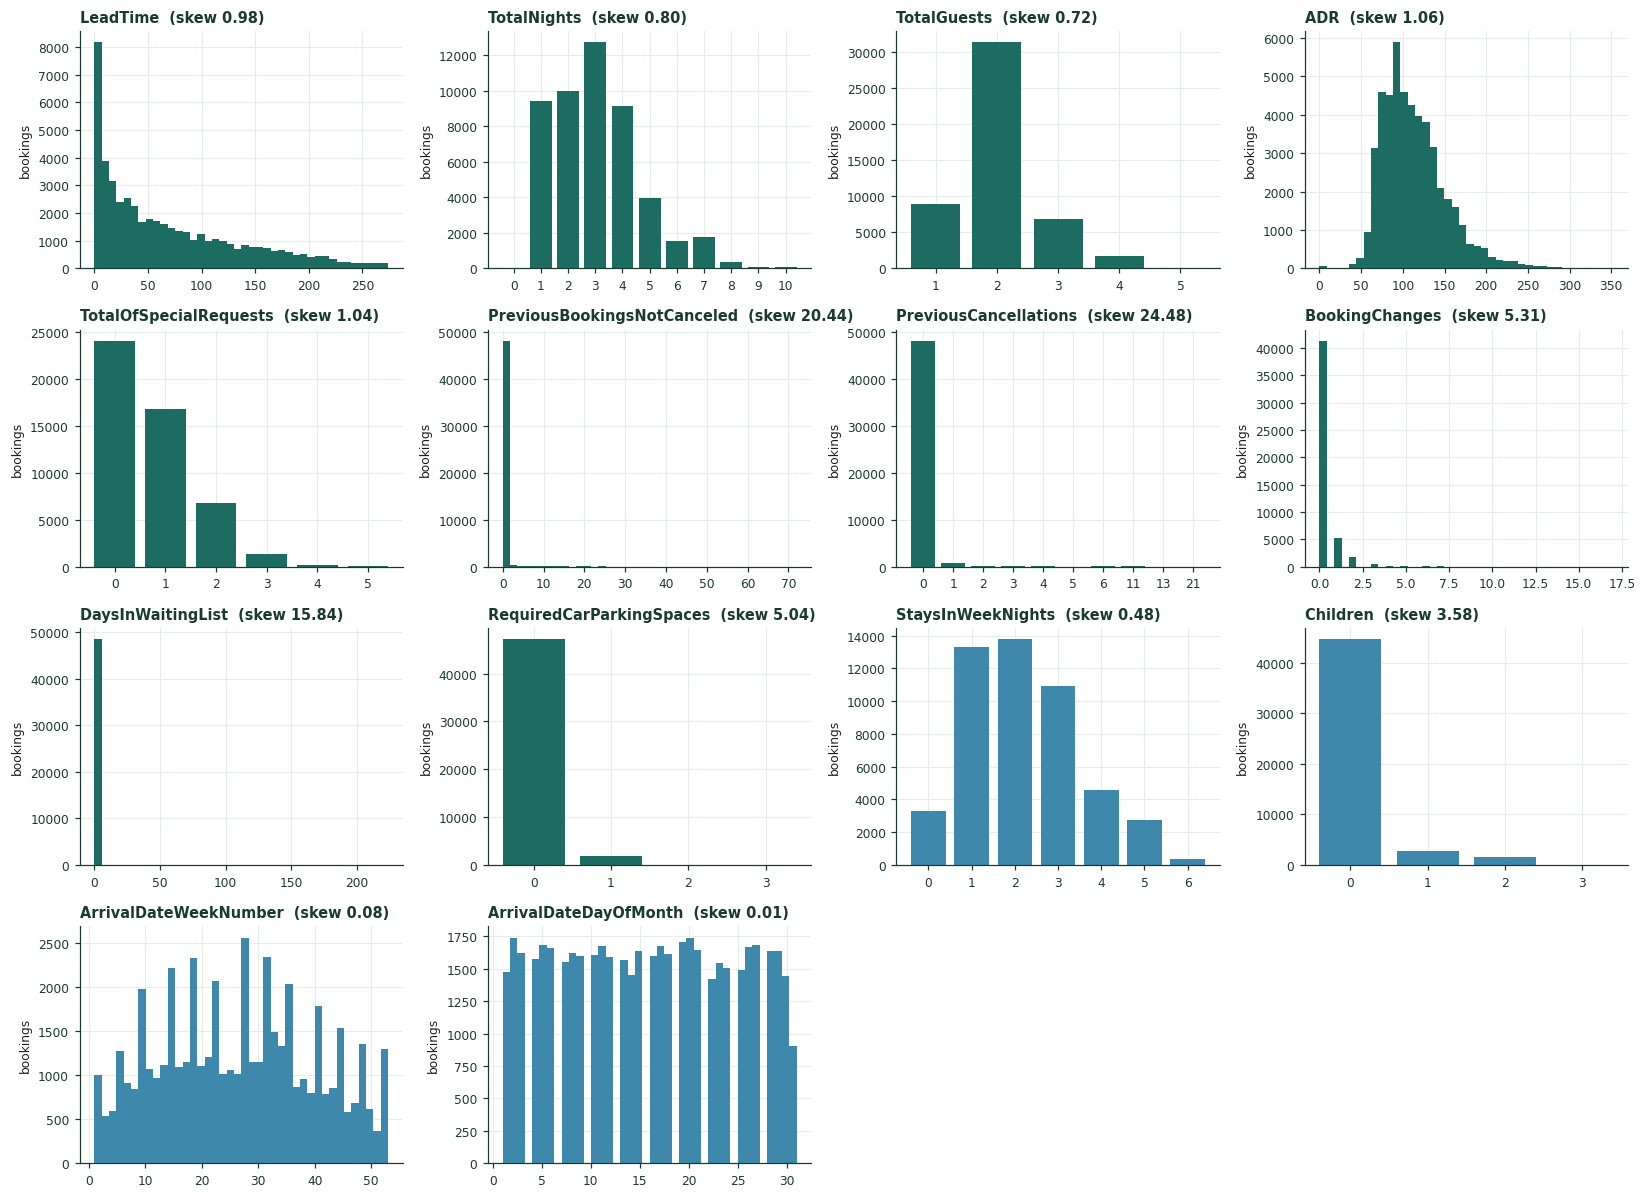

,count,mean,std,min,25%,50%,75%,max
LeadTime,48990.0,70.33,66.95,0.0,14.0,49.00,111.0,274.0
TotalNights,48990.0,3.05,1.62,0.0,2.0,3.00,4.0,10.0
TotalGuests,48990.0,2.03,0.69,1.0,2.0,2.00,2.0,5.0
ADR,48990.0,112.93,38.08,0.0,85.5,106.25,134.3,352.5
TotalOfSpecialRequests,48990.0,0.71,0.83,0.0,0.0,1.00,1.0,5.0
PreviousBookingsNotCanceled,48990.0,0.18,2.02,0.0,0.0,0.00,0.0,72.0
PreviousCancellations,48990.0,0.03,0.36,0.0,0.0,0.00,0.0,21.0
BookingChanges,48990.0,0.23,0.65,0.0,0.0,0.00,0.0,17.0
DaysInWaitingList,48990.0,0.65,7.67,0.0,0.0,0.00,0.0,224.0
RequiredCarParkingSpaces,48990.0,0.04,0.19,0.0,0.0,0.00,0.0,3.0


In [465]:
#candidates maybe
NUM_CAND = ["LeadTime", "TotalNights", "TotalGuests", "ADR", "TotalOfSpecialRequests", "PreviousBookingsNotCanceled", "PreviousCancellations", "BookingChanges", "DaysInWaitingList" , "RequiredCarParkingSpaces"]
#every numeric column
NUM_ALL = NUM_CAND + ["StaysInWeekNights", "Children", "ArrivalDateWeekNumber", "ArrivalDateDayOfMonth"]

fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, col in zip(axes.ravel(), NUM_ALL):
    discrete = df[col].nunique() <= 12
    if discrete:   # few distinct values -> one bar per value
        vc = df[col].value_counts().sort_index()
        ax.bar(vc.index.astype(str), vc.values, color=deepgreen if col in NUM_CAND else verdigris)
    else:
        ax.hist(df[col], bins=40, color=deepgreen if col in NUM_CAND else verdigris)
    ax.set_title(f"{col}  (skew {df[col].skew():.2f})", fontsize=9.5)
    ax.set_ylabel("bookings", fontsize=8); ax.tick_params(labelsize=8)
for ax in axes.ravel()[len(NUM_ALL):]:
    ax.set_visible(False)
plt.tight_layout(); save("01_numeric_distributions.png"); plt.show()

df[NUM_ALL].describe().T.round(2)

The skew in each decides the transformations needed later.

- the heavily skewed data would make the centroids drift towards them 
- discrete values will help explain patterns later
- will drop almost constant features will be dropped 
- seeing the scale of the features so we can standardize later so it is not all driven by larger scales
Columns outside the candidate list:
- **StaysInWeekNights** and **Children** are kept only to describe the clusters later 
- **ArrivalDateWeekNumber** and **ArrivalDateDayOfMonth** have a skew of almost zero and they describe when and not actually what kind of booking it is

Categorical columns

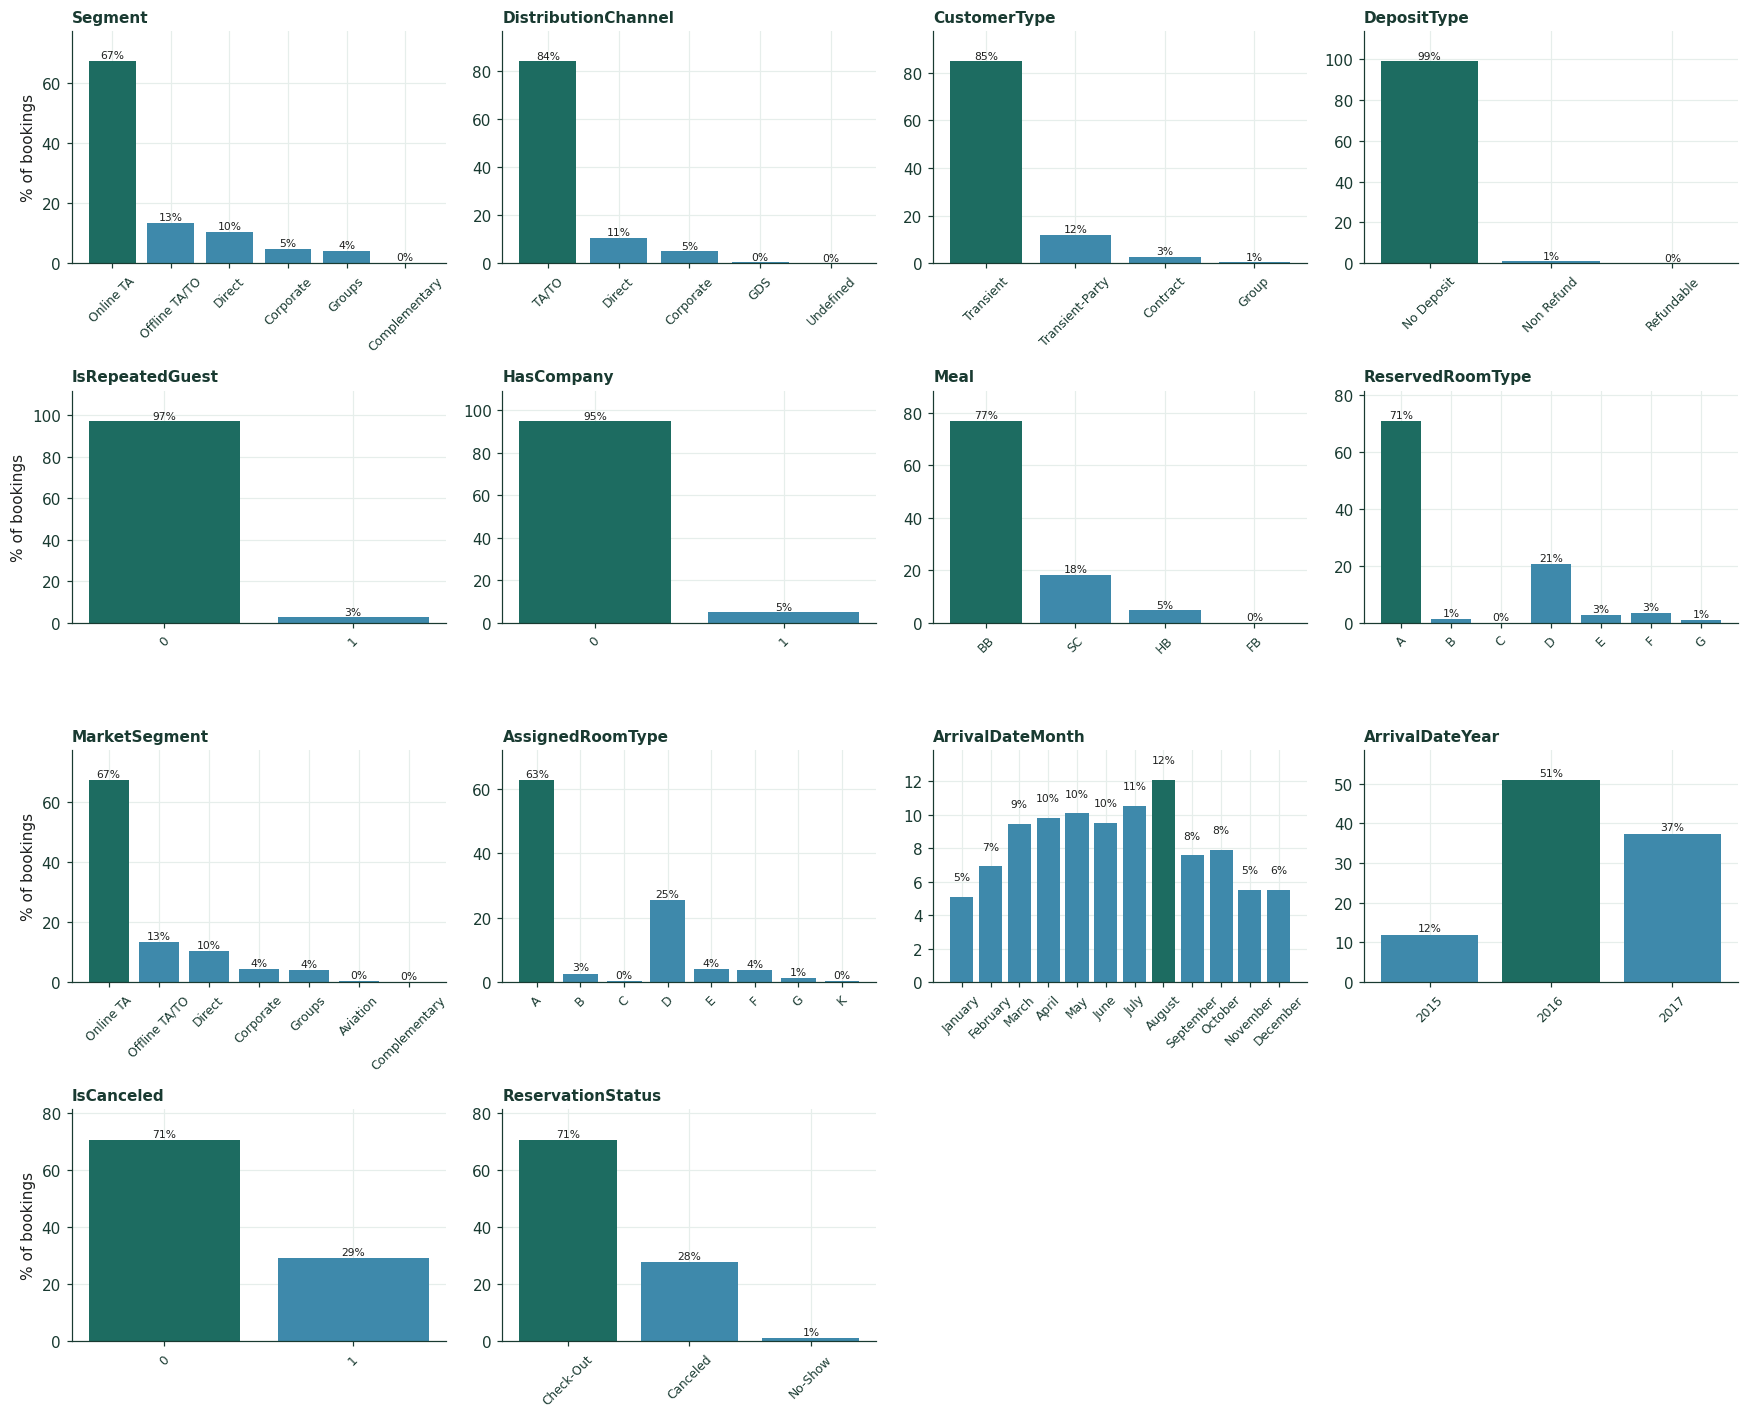

In [466]:
CAT_CAND = ["Segment", "DistributionChannel", "CustomerType", "DepositType", "IsRepeatedGuest", "HasCompany", "Meal", "ReservedRoomType",]
CAT_ALL = CAT_CAND + ["MarketSegment", "AssignedRoomType", "ArrivalDateMonth", "ArrivalDateYear", "IsCanceled", "ReservationStatus"]
MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, col in zip(axes.ravel(), CAT_ALL):
    vc = df[col].value_counts(normalize=True).mul(100)
    if col == "ArrivalDateMonth":
        vc = vc.reindex(MONTHS)            # calendar order instead of size order
    elif col in ["ArrivalDateYear", "ReservedRoomType", "AssignedRoomType"]:
        vc = vc.sort_index()
    colors = [deepgreen if v == vc.max() else verdigris for v in vc.values]   # largest level highlighted
    ax.bar(vc.index.astype(str), vc.values, color=colors)
    ax.set_title(col, fontsize=10); ax.tick_params(axis="x", rotation=45, labelsize=8)
    for i, v in enumerate(vc.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=7)
    ax.set_ylim(0, vc.max() * 1.15)
for ax in axes[:, 0]:
    ax.set_ylabel("% of bookings")
for ax in axes.ravel()[len(CAT_ALL):]:
    ax.set_visible(False)
plt.tight_layout(); save("02_categorical_distributions.png"); plt.show()


* **Online TA** sells two thirds of all bookings, so a segment split will be uneven
* **IsRepeatedGuest** is rare and so if it were z scored the 1s would land several standard devs away and dominate the distances 
* **DepositType** is almost always No Deposit
* **ArrivalDateMonth:** peaks in summer (August 12%) and is lowest in winter (January 5%) 
* **ArrivalDateYear:** the data covers mid-2015 to mid-2017, so 2016 is the only full year so it doesnt really make sense to keep it
* **IsCanceled / ReservationStatus** are the outcome of the booking so othey can never be clustering inputs

In [467]:
#number of values in country and agent
df[["Country", "Agent"]].nunique().rename({"Country": "countries", "Agent": "agents"})

countries    166
agents       219
dtype: int64

those columns have too many levels for one bar each, so the 15 most common are shown and the rest are grouped as "other".

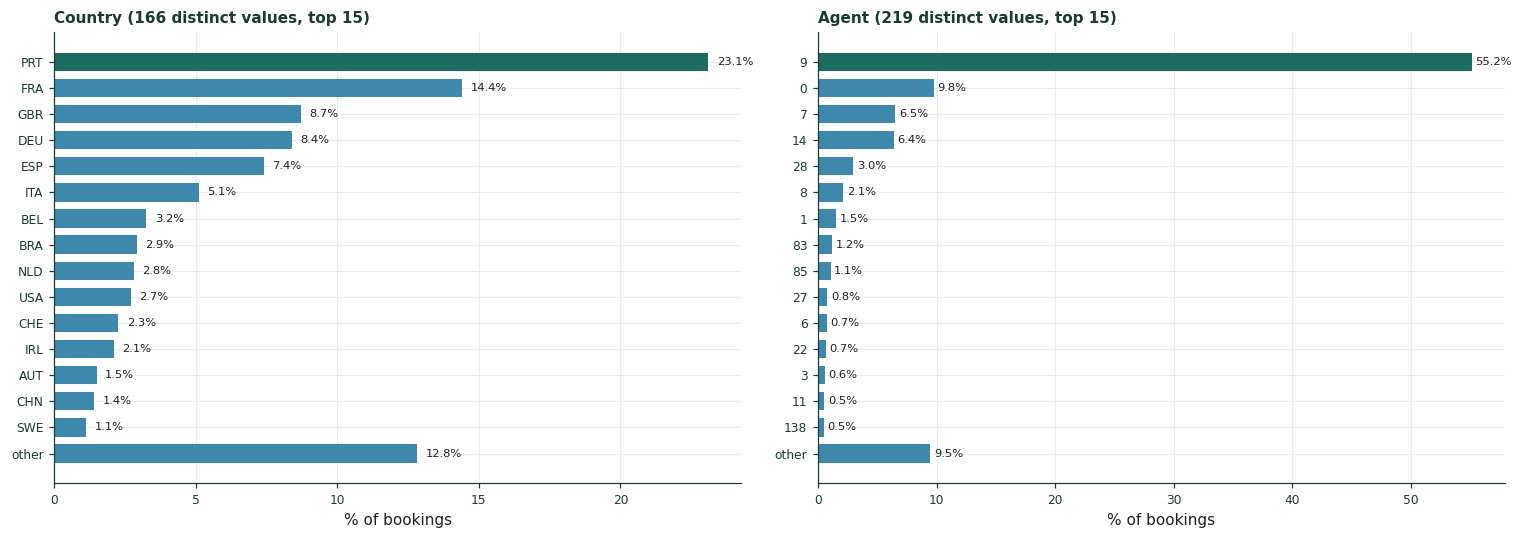

In [468]:
HIGH_CARD = ["Country", "Agent"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, HIGH_CARD):
    vc = df[col].astype(str).value_counts(normalize=True).mul(100)
    top = vc.head(15)
    top["other"] = vc.iloc[15:].sum()
    top = top[::-1]                                   # largest at the top
    colors = [deepgreen if v == top.drop("other").max() else verdigris for v in top.values]
    ax.barh(top.index, top.values, color=colors, height=0.7)
    for y, v in enumerate(top.values):
        ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=7.5)
    ax.set_title(f"{col} ({df[col].nunique()} distinct values, top 15)", fontsize=10)
    ax.set_xlabel("% of bookings"); ax.tick_params(labelsize=8)
plt.tight_layout(); save("02b_high_cardinality.png"); plt.show()

One-hot encoding either column would add many sparse 0/1 columns that would swamp the 11 real features in the distances, so neither is used as an input

## 4 EDA: correlation between candidate features

Two features that carry the same information would count that trait twice in the Euclidean distance. So for any highly correlated pair keeps only one member.

Numeric (Spearman is used becuase it can see non linear relationships)

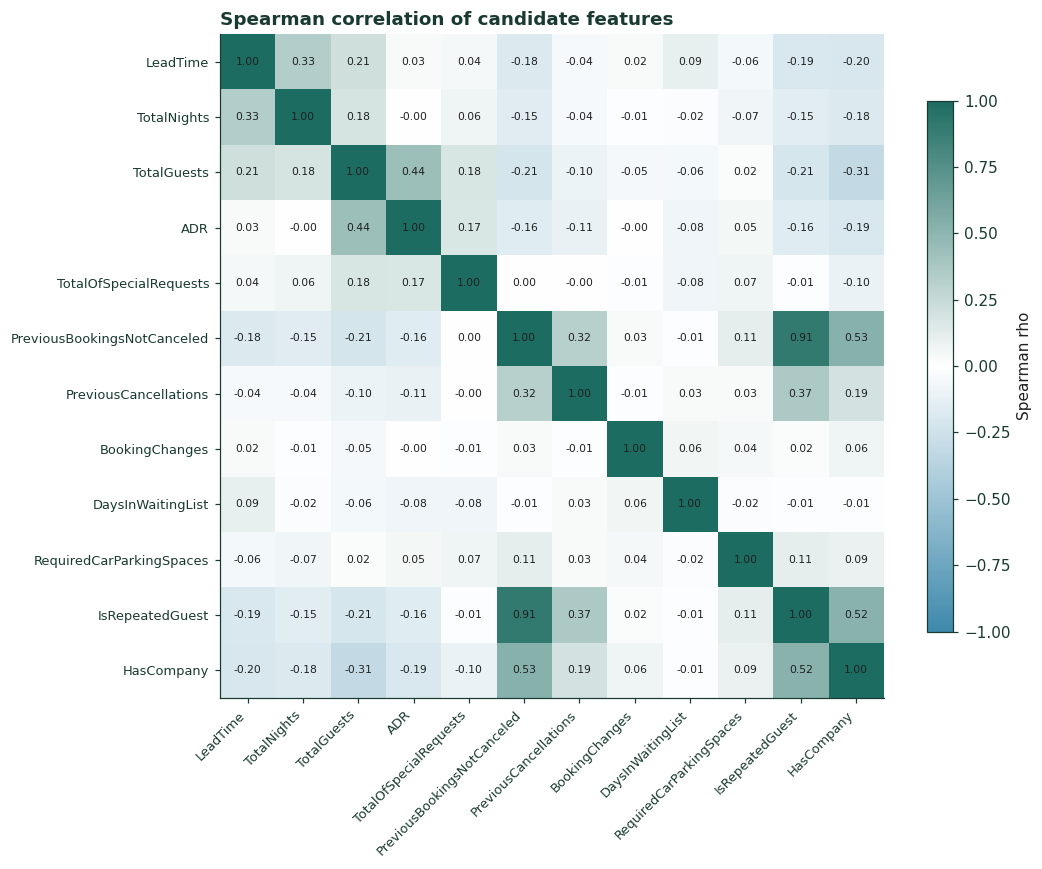

,feature A,feature B,rho
0,PreviousBookingsNotCanceled,IsRepeatedGuest,0.91
1,PreviousBookingsNotCanceled,HasCompany,0.53
2,IsRepeatedGuest,HasCompany,0.52
3,TotalGuests,ADR,0.44
4,PreviousCancellations,IsRepeatedGuest,0.37
5,LeadTime,TotalNights,0.33
6,PreviousBookingsNotCanceled,PreviousCancellations,0.32
7,TotalGuests,HasCompany,-0.31


In [469]:

CORR_COLS = NUM_CAND + ["IsRepeatedGuest", "HasCompany"]
rho = df[CORR_COLS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(rho.values, cmap=div_cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(rho)), rho.columns, rotation=45, ha="right", fontsize=8.5)
ax.set_yticks(range(len(rho)), rho.index, fontsize=8.5)
for i in range(len(rho)):
    for j in range(len(rho)):
        ax.text(j, i, f"{rho.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman rho")
ax.set_title("Spearman correlation of candidate features")
plt.tight_layout(); save("03_spearman_heatmap.png"); plt.show()

# strongest pairs (upper triangle only, so each pair appears once)
pairs = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
(pairs.rename("rho").sort_values(key=abs, ascending=False).head(8).round(2)
      .rename_axis(["feature A", "feature B"]).reset_index())   # one full row per pair

**Categorical (Cramér's V, 0 = unrelated, 1 = one fully determines the other).**

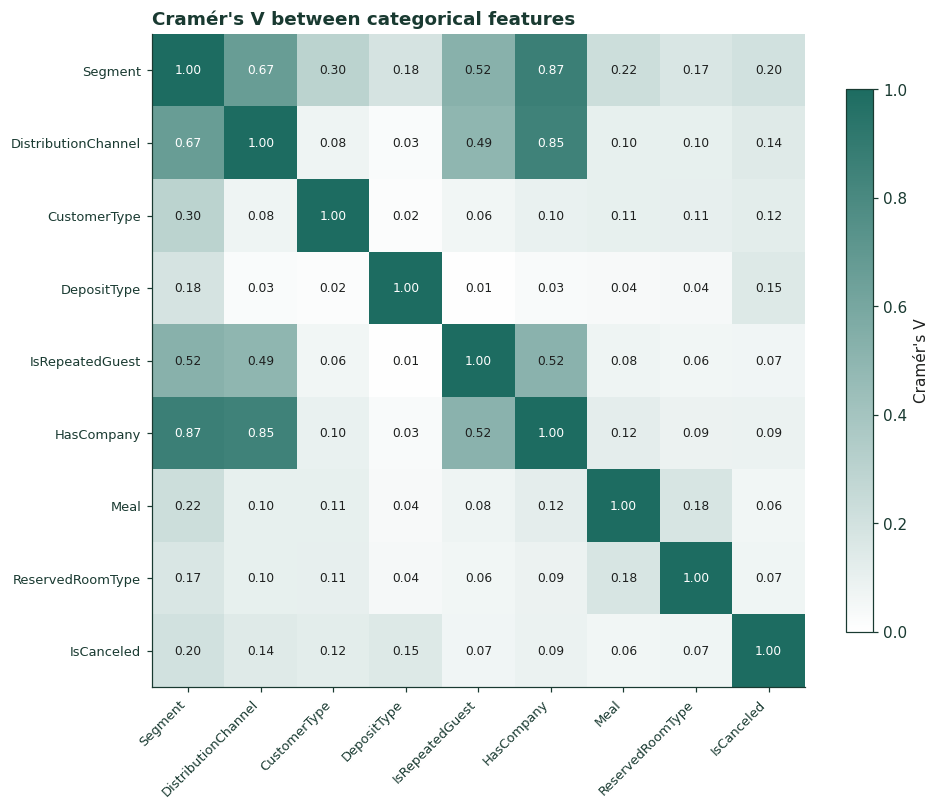

,feature A,feature B,V
0,Segment,HasCompany,0.87
1,DistributionChannel,HasCompany,0.85
2,Segment,DistributionChannel,0.67
3,Segment,IsRepeatedGuest,0.52
4,IsRepeatedGuest,HasCompany,0.52
5,DistributionChannel,IsRepeatedGuest,0.49
6,Segment,CustomerType,0.30
7,Segment,Meal,0.22


In [470]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

CAT_V = CAT_CAND + ["IsCanceled"]   # every categorical candidate; IsCanceled for reference only
cv = pd.DataFrame([[cramers_v(df[a], df[b]) for b in CAT_V] for a in CAT_V], index=CAT_V, columns=CAT_V)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cv.values, cmap=LinearSegmentedColormap.from_list("seq", ["#ffffff", deepgreen]), vmin=0, vmax=1)
ax.set_xticks(range(len(cv)), cv.columns, rotation=45, ha="right", fontsize=8.5)
ax.set_yticks(range(len(cv)), cv.index, fontsize=8.5)
for i in range(len(cv)):
    for j in range(len(cv)):
        ax.text(j, i, f"{cv.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if cv.values[i, j] > 0.6 else darkjungle)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Cramér's V")
ax.set_title("Cramér's V between categorical features")
plt.tight_layout(); save("04_cramers_v_heatmap.png"); plt.show()

# strongest pairs (upper triangle only, so each pair appears once)
cv_pairs = cv.where(np.triu(np.ones(cv.shape, dtype=bool), k=1)).stack()
(cv_pairs.rename("V").sort_values(ascending=False).head(8).round(2)
      .rename_axis(["feature A", "feature B"]).reset_index())   # one full row per pair


In [471]:
# save the full dataset with the added cols
df.to_csv("H2_notdropped.csv", index=False)


# dropped above 0.7
REDUNDANT = {"PreviousBookingsNotCanceled", "HasCompany", "DistributionChannel"}
df = df.drop(columns=list(REDUNDANT))
print("dropped:", list(REDUNDANT))


dropped: ['DistributionChannel', 'HasCompany', 'PreviousBookingsNotCanceled']


## 5 EDA: leakage checks

A feature that is filled in after the booking, or that almost fixes the outcome, would make the clusters split "canceled" from "not canceled"

,not canceled,canceled,total
no parking,32856,14348,47204
parking,1786,0,1786
all,34642,14348,48990


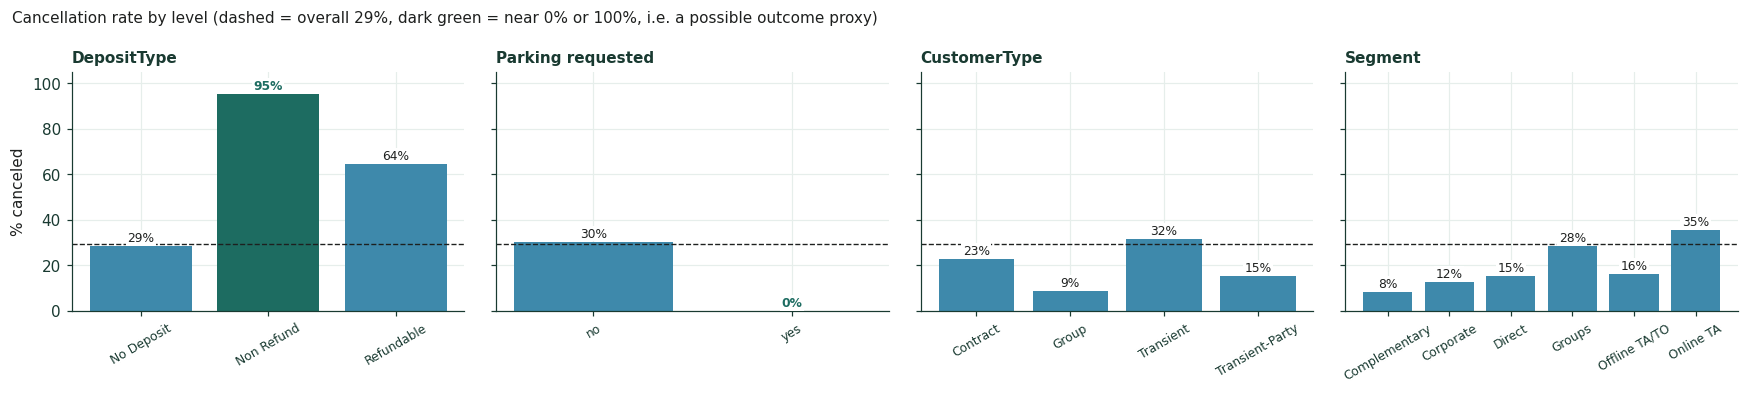

In [472]:
park = pd.crosstab(df["RequiredCarParkingSpaces"] > 0, df["IsCanceled"], margins=True)
park.index = ["no parking", "parking", "all"]
park.columns = ["not canceled", "canceled", "total"]
display(park)

checks = {
    "DepositType": df.groupby("DepositType")["IsCanceled"].mean() * 100,
    "Parking requested": df.groupby(df["RequiredCarParkingSpaces"] > 0)["IsCanceled"].mean().rename({False: "no", True: "yes"}) * 100,
    "CustomerType": df.groupby("CustomerType")["IsCanceled"].mean() * 100,
    "Segment": df.groupby("Segment")["IsCanceled"].mean() * 100,
}
overall = df["IsCanceled"].mean() * 100
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (name, s) in zip(axes, checks.items()):
    bars = ax.bar(s.index.astype(str), s.values, color=[(deepgreen if (v < 2 or v > 90) else verdigris) for v in s.values])   # deepgreen = suspicious level
    for b, v in zip(bars, s.values):
        flag = v < 2 or v > 90
        ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v:.0f}%", ha="center", fontsize=8,
                color=deepgreen if flag else darkjungle, fontweight="bold" if flag else "normal",
                bbox=dict(facecolor="white", edgecolor="none", pad=1))   # readable over the dashed line
    ax.axhline(overall, color=darkjungle, ls="--", lw=0.9)
    ax.set_title(name, fontsize=10); ax.tick_params(axis="x", rotation=30, labelsize=8)
axes[0].set_ylabel("% canceled"); axes[0].set_ylim(0, 105)
fig.suptitle(f"Cancellation rate by level (dashed = overall {overall:.0f}%, dark green = near 0% or 100%, i.e. a possible outcome proxy)", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); save("05_leakage_checks.png"); plt.show()

## 6 Feature selection

Every column of the data, with whether it is used as a clustering input and why.

| Feature | Known at booking | Outcome / proxy | Used | Reason |
|---|---|---|---|---|
| **used as clustering inputs** | | | | |
| **LeadTime** | yes | no | **yes** | how far ahead the guest plans |
| **TotalNights** | yes | no | **yes** | length of stay (weekend + week nights) |
| **TotalGuests** | yes | no | **yes** | party size (adults + children + babies) |
| **ADR** | yes | no | **yes** | price level of the booking |
| **TotalOfSpecialRequests** | yes | no | **yes** | guest engagement |
| **IsRepeatedGuest** | yes | no | **yes** | loyalty |
| **Segment** | yes | no | **yes** | how the booking was sold (rare levels merged) |
| **repeat another feature** | | | | |
| MarketSegment | yes | no | no | raw version of Segment|
| StaysInWeekendNights | yes | no | no | already inside TotalNights|
| Adults | yes | no | no | already inside TotalGuests, would count party size twice |
| Babies | yes | no | no | already inside TotalGuests; 0 for almost every booking |
| StaysInWeekNights | yes | no | no | already inside TotalNights|
| Children | yes | no | no | already inside TotalGuests|
| PreviousBookingsNotCanceled | yes | no | no | ρ = 0.91 with IsRepeatedGuest |
| DistributionChannel | yes | no | no | coarser copy of Segment (Cramer's V = 0.67) |
| HasCompany | yes | no | no | almost the same as Segment = Corporate (V = 0.87) |
| CustomerType | yes | no | no | overlaps Segment (V = 0.30)|
| ReservedRoomType | yes | no | no | 71% room A follows price, so ADR already carries it |
| **carry too little information** | | | | |
| PreviousCancellations | yes | no | no | 0 for almost every booking  |
| Meal | yes | no | no | close to constant |
| **would dominate the distances** | | | | |
| Country | yes | no | no | |
| Agent | yes | no | no |  |
| **describe when, not what kind of booking** | | | | |
| ArrivalDateMonth | yes | no | no | season, not booking type |
| ArrivalDateWeekNumber | yes | no | no | almost flat distribution |
| ArrivalDateDayOfMonth | yes | no | no | almost flat distribution |
| ArrivalDateYear | yes | no | no | only reflects the data collection period|
| **outcome proxies (leakage)** | | | | |
| DepositType | yes | proxy | no | Non Refund cancels 95% of the time  |
| RequiredCarParkingSpaces | no | proxy | no | 0% cancellation, recorded at arrival  |
| **not known at booking time** | | | | |
| BookingChanges | no | no | no | keeps changing until checkin or cancellation |
| DaysInWaitingList | no | no | no | only known once the booking is confirmed |
| AssignedRoomType | no | no | no | set at check in (differs from the reserved room for 11% of bookings) |
| **the outcome itself** | | | | |
| IsCanceled | no | YES | no | |
| ReservationStatus | no | YES | no | |
| ReservationStatusDate | no | YES | no | |

**Final clustering features (7 source variables):** LeadTime, TotalNights, TotalGuests, ADR, TotalOfSpecialRequests, IsRepeatedGuest, Segment

In [473]:
# keep only the 7 source variables chosen in 6
MODEL_COLS = ["LeadTime", "TotalNights", "TotalGuests", "ADR", "TotalOfSpecialRequests", "IsRepeatedGuest", "Segment"]

dropped = [col for col in df.columns if col not in MODEL_COLS]
df = df[MODEL_COLS]
print(f"dropped {len(dropped)} columns:", dropped)
print("kept:", list(df.columns), df.shape)


dropped 24 columns: ['IsCanceled', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country', 'MarketSegment', 'PreviousCancellations', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'Agent', 'DaysInWaitingList', 'CustomerType', 'RequiredCarParkingSpaces', 'ReservationStatus', 'ReservationStatusDate']
kept: ['LeadTime', 'TotalNights', 'TotalGuests', 'ADR', 'TotalOfSpecialRequests', 'IsRepeatedGuest', 'Segment'] (48990, 7)


## 7. Transformation and scaling

| Columns | Step | Why |
|---|---|---|
| LeadTime, TotalNights, TotalOfSpecialRequests | log(1 + x) then z-score | right-skewed, so a few long stays or early bookings would otherwise dominate |
| ADR, TotalGuests | z-score only | ADR is only moderately skewed (1.06) after outlier cleaning. log1p would over-correct it to a strong left skew (−2.27) and push the few near-free stays far away, where they would form their own artificial cluster|
| IsRepeatedGuest | kept as 0/1 | a z-score would put the rare 1s many standard deviations away |
| Segment | one-hot × 1/√2 | two different segments are then exactly distance 1 apart |

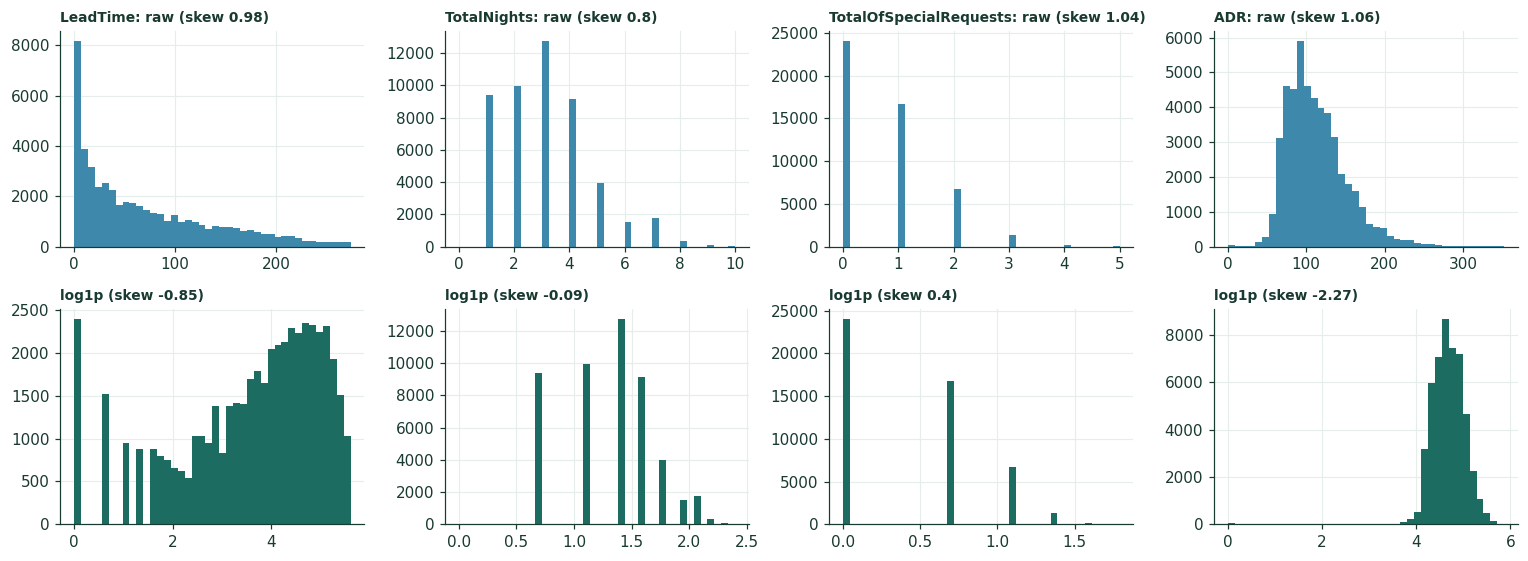

,raw,log1p
LeadTime,0.98,-0.85
TotalNights,0.80,-0.09
TotalOfSpecialRequests,1.04,0.40
ADR,1.06,-2.27


In [474]:
NUM_LOG = ["LeadTime", "TotalNights", "TotalOfSpecialRequests"]
NUM_LIN = ["ADR", "TotalGuests"]
BIN = ["IsRepeatedGuest"]
CAT = ["Segment"]

SKEW_COLS = NUM_LOG + ["ADR"]
skew = pd.DataFrame({"raw": df[SKEW_COLS].skew(), "log1p": np.log1p(df[SKEW_COLS]).skew()}).round(2)
fig, axes = plt.subplots(2, 4, figsize=(14, 5.2))
for j, col in enumerate(SKEW_COLS):
    axes[0, j].hist(df[col], bins=40, color=verdigris)
    axes[0, j].set_title(f"{col}: raw (skew {skew.loc[col, 'raw']})", fontsize=9)
    axes[1, j].hist(np.log1p(df[col]), bins=40, color=deepgreen)
    axes[1, j].set_title(f"log1p (skew {skew.loc[col, 'log1p']})", fontsize=9)
plt.tight_layout(); save("06_log_transform.png"); plt.show()
skew

In [475]:
num = np.log1p(df[NUM_LOG]).join(df[NUM_LIN])
num = pd.DataFrame(StandardScaler().fit_transform(num), columns=num.columns)
onehot = pd.get_dummies(df[CAT], prefix="", prefix_sep="", dtype=float) / np.sqrt(2)
X_df = pd.concat([num, df[BIN].astype(float), onehot], axis=1)

print("model matrix:", X_df.shape)
X_df.describe().T.round(2)[["mean", "std", "min", "max"]]

model matrix: (48990, 12)


,mean,std,min,max
LeadTime,0.00,1.00,-2.42,1.40
TotalNights,0.00,1.00,-3.29,2.69
TotalOfSpecialRequests,0.00,1.00,-0.95,3.00
ADR,0.00,1.00,-2.97,6.29
TotalGuests,-0.00,1.00,-1.49,4.29
IsRepeatedGuest,0.03,0.16,0.00,1.00
Complementary,0.00,0.02,0.00,0.71
Corporate,0.03,0.15,0.00,0.71
Direct,0.07,0.22,0.00,0.71
Groups,0.03,0.14,0.00,0.71


## 8 Checks on the final matrix

**Spread per column.** The numeric features now share a scale (mean 0, std 1), shown as box plots. The 0/1 and one-hot columns only take two values, so a box plot says nothing about them; instead the share of bookings in each category is shown. Their gap (1 for IsRepeatedGuest, 1 between two segments) is about one standard deviation, so no single column dominates the distances.

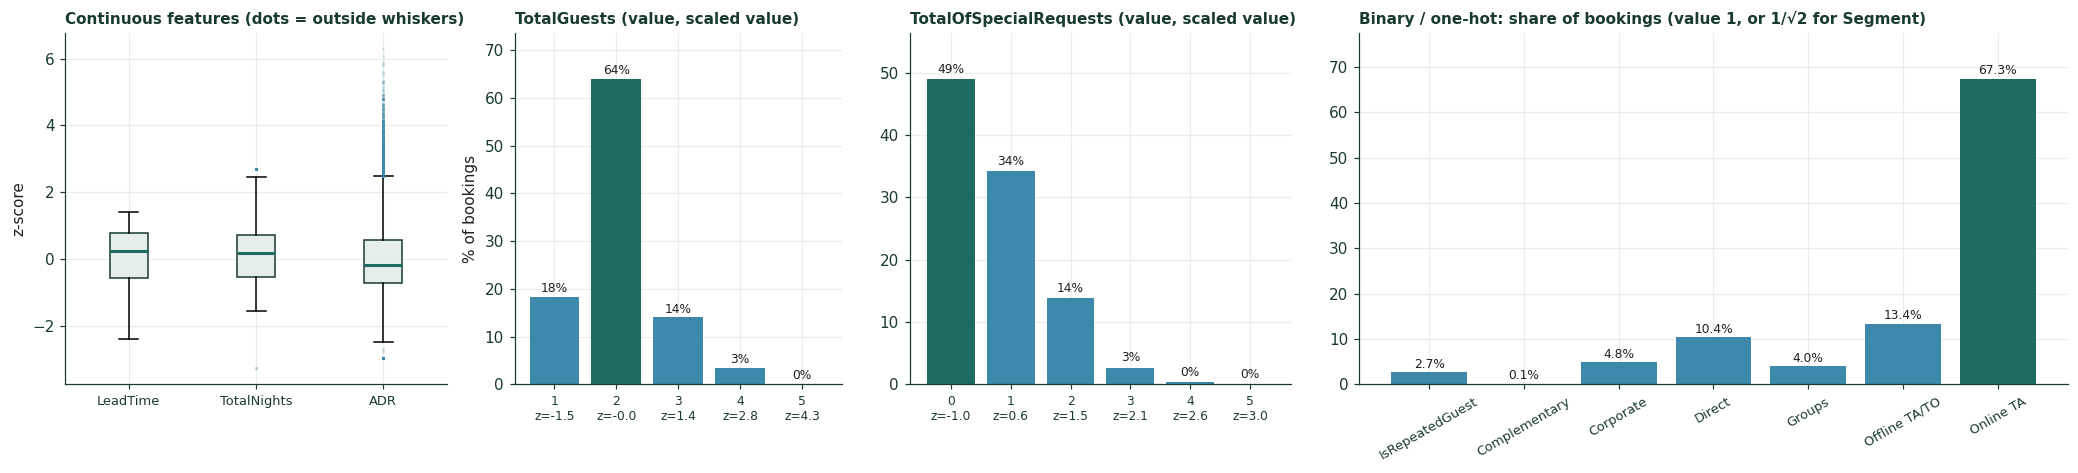

In [476]:
CONT = ["LeadTime", "TotalNights", "ADR"]               # continuous -> box plots
DISC = ["TotalGuests", "TotalOfSpecialRequests"]        # only a few whole-number values -> bars
CAT_COLS = [col for col in X_df.columns if col not in CONT + DISC]   # IsRepeatedGuest + Segment one-hot

fig, axes = plt.subplots(1, 4, figsize=(19, 4.4), gridspec_kw={"width_ratios": [3.5, 3, 3.5, 6.5]})

# continuous: spread after scaling
ax = axes[0]
ax.boxplot([X_df[col] for col in CONT], showfliers=True, patch_artist=True,
           flierprops=dict(marker="o", markersize=2, markerfacecolor=verdigris, markeredgecolor="none", alpha=0.15),
           boxprops=dict(facecolor=mist, edgecolor=mediumjungle), medianprops=dict(color=deepgreen, lw=2))
ax.set_xticks(range(1, len(CONT) + 1), CONT, fontsize=8.5)
ax.set_ylabel("z-score"); ax.set_title("Continuous features (dots = outside whiskers)", fontsize=10)

# discrete: one bar per value, labelled with the original value and where it lands after scaling
for ax, col in zip(axes[1:3], DISC):
    share = df[col].value_counts(normalize=True).sort_index().mul(100)
    z = pd.Series(X_df[col].values, index=df[col].values).groupby(level=0).first()
    ax.bar([f"{v}\nz={z[v]:.1f}" for v in share.index], share.values,
           color=[deepgreen if s == share.max() else verdigris for s in share.values])
    for i, s in enumerate(share.values):
        ax.text(i, s + 1, f"{s:.0f}%", ha="center", fontsize=8)
    ax.set_ylim(0, share.max() * 1.15); ax.tick_params(axis="x", labelsize=8)
    ax.set_title(f"{col} (value, scaled value)", fontsize=10)
axes[1].set_ylabel("% of bookings")

# 0/1 and one-hot columns: share of bookings in each category
ax = axes[3]
share = (X_df[CAT_COLS] > 0).mean().mul(100)
ax.bar(share.index, share.values, color=[deepgreen if v == share.max() else verdigris for v in share.values])
for i, v in enumerate(share.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=8)
ax.set_ylim(0, share.max() * 1.15); ax.tick_params(axis="x", rotation=30, labelsize=8.5)
ax.set_title("Binary / one-hot: share of bookings (value 1, or 1/√2 for Segment)", fontsize=10)
plt.tight_layout(); save("07_scaled_features_boxplot.png"); plt.show()


**Correlation of the final numeric inputs.** The strongest remaining pair is TotalGuests and ADR. No pair is high enough to count the same trait twice.

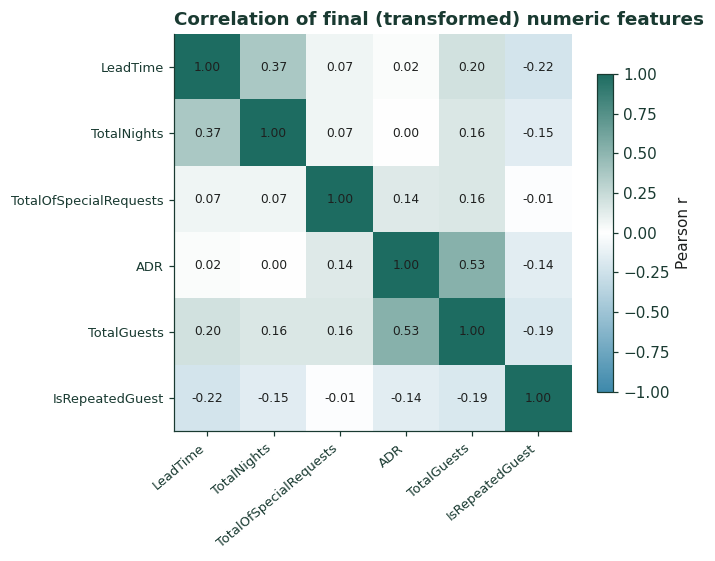

In [477]:
final_num = NUM_LOG + NUM_LIN + BIN
r = X_df[final_num].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(r.values, cmap=div_cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(r)), r.columns, rotation=40, ha="right", fontsize=8.5)
ax.set_yticks(range(len(r)), r.index, fontsize=8.5)
for i in range(len(r)):
    for j in range(len(r)):
        ax.text(j, i, f"{r.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation of final (transformed) numeric features")
plt.tight_layout(); save("08_final_feature_correlation.png"); plt.show()


## 9 Save the dataset

`H2_Cleaned_clustering.csv` holds only the model columns (scaled, ready for K-Means)

The raw values used to describe the clusters afterwards come from `H2_notdropped.csv`, saved before any column was dropped


In [478]:
X_df.to_csv("H2_Cleaned_clustering.csv", index=False)
print("saved H2_Cleaned_clustering.csv:", X_df.shape)
print("model columns:", list(X_df.columns))


saved H2_Cleaned_clustering.csv: (48990, 12)
model columns: ['LeadTime', 'TotalNights', 'TotalOfSpecialRequests', 'ADR', 'TotalGuests', 'IsRepeatedGuest', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA']
